In [29]:
## df mit der pickle datei einlesen

import pandas as pd

df = pd.read_pickle("customer_train_typed.pkl")

In [30]:
## nach Education level Gruppieren

education_groups = df.groupby("education_level")
print(education_groups.size())

education_level
Primary School      308
High School        2017
Graduate          11598
Masters            4361
Phd                 414
dtype: int64


 Anzahl der Personen und Jobsuchenden ermitteln:

Hier passiert Folgendes:

* count: Zählt alle Personen innerhalb der jeweiligen Gruppe.
* sum: Addiert die Boolean-Werte. Bei Boolean-Werten entspricht True einer 1 und False einer 0. Dadurch erhalten wir die Anzahl der wechselwilligen Personen.


In [31]:
education_analysis = education_groups["job_change"].agg(
    total_students="count",
    job_seekers="sum"
)

In [32]:
## Anteil der Jobsuchenden Berechnen:
education_analysis["proportion"] = (
    education_analysis["job_seekers"] / education_analysis["total_students"]
)

In [33]:
## in Prozent umrechnen:
education_analysis["percentage"] = education_analysis["proportion"] * 100

In [34]:
print(education_analysis)

                 total_students  job_seekers  proportion  percentage
education_level                                                     
Primary School              308           41    0.133117   13.311688
High School                2017          394    0.195340   19.533961
Graduate                  11598         3245    0.279790   27.978962
Masters                    4361          935    0.214400   21.440037
Phd                         414           58    0.140097   14.009662


Bei dieser Analyse werden die Missing Values in Education Level ausgeschlossen!

-------Jetzt machen wir ein Barplot Diagram mit Seaborn

In [35]:
## education level als index resetten, da seaborn dann besser arbeitet
education_plot = education_analysis.reset_index()

In [36]:
%pip install seaborn


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


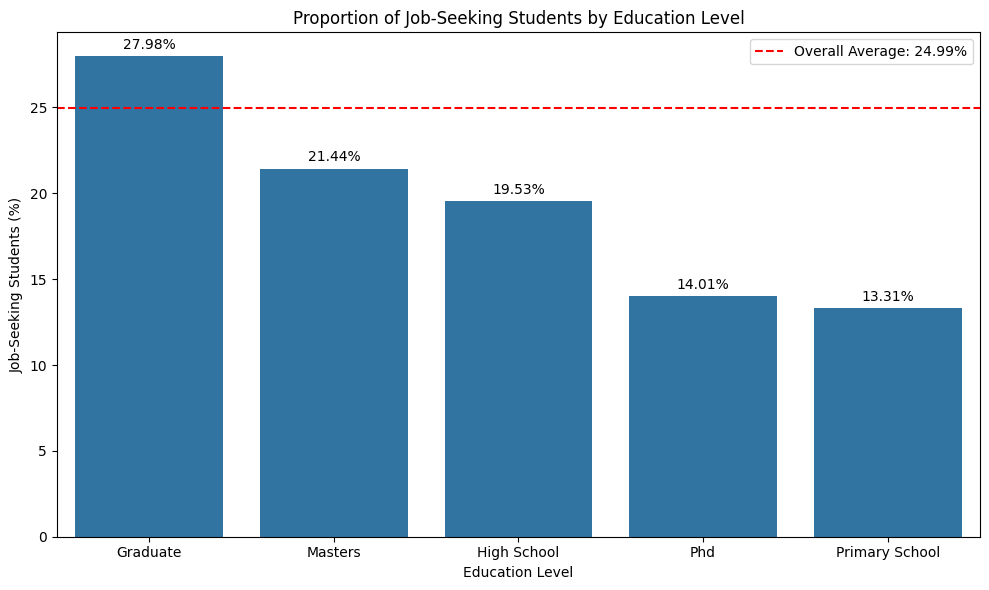

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

# Prepare and sort data by percentage (descending)
education_plot = education_analysis.reset_index()

education_plot = education_plot[
    education_plot["education_level"].notna()
].sort_values(by="percentage", ascending=False)

# Calculate overall weighted average job-change rate
average_percentage = (
    education_analysis["job_seekers"].sum()
    / education_analysis["total_students"].sum()
    * 100
)

# Create barplot
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=education_plot,
    x="education_level",
    y="percentage",
    order=education_plot["education_level"]
)

# Add percentage labels above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

# Add horizontal line for overall average
plt.axhline(
    y=average_percentage,
    color="red",
    linestyle="--",
    label=f"Overall Average: {average_percentage:.2f}%"
)

# Customize plot
plt.xlabel("Education Level")
plt.ylabel("Job-Seeking Students (%)")
plt.title("Proportion of Job-Seeking Students by Education Level")
plt.legend()
plt.tight_layout()

plt.show()

--------
AQ2
--------

In [38]:
df2 = pd.read_pickle("customer_train_typed.pkl")
df2[["training_hours", "job_change"]].describe()

,training_hours
count,19158.000000
mean,65.366896
std,60.058462
min,1.000000
25%,23.000000
50%,47.000000
75%,88.000000
max,336.000000


Aus den einzelnen ratio Zahlen Kategorien machen:

In [39]:
bins = [0, 25, 50, 75, 100, 125, 150, 175, 200, 250, 300, 400]
labels = ["1-25", "26-50", "51-75", "76-100", "101-125","126 - 150", "151-175", "176-200", "201-250","251-300","301-400"]

df["hours_group"] = pd.cut(
    df["training_hours"],
    bins=bins,
    labels=labels,
    right=True
)

df["hours_group"].value_counts().sort_index()

hours_group
1-25         5395
26-50        4798
51-75        2984
76-100       2113
101-125      1305
126 - 150     784
151-175       650
176-200       327
201-250       390
251-300       214
301-400       198
Name: count, dtype: int64

Anteil der Jobsuchenden an der gesamtgruppe der training_hours_completed berechnen

In [40]:
hours_groups = df.groupby("hours_group", observed=True)

hours_analysis = hours_groups["job_change"].agg(
    total_students="count",
    job_seekers="sum"
)

hours_analysis["proportion"] = (
    hours_analysis["job_seekers"] / hours_analysis["total_students"]
)
hours_analysis["percentage"] = hours_analysis["proportion"] * 100

hours_analysis

,total_students,job_seekers,proportion,percentage
hours_group,,,,
1-25,5395,1362,0.252456,25.245598
26-50,4798,1242,0.258858,25.885786
51-75,2984,739,0.247654,24.765416
76-100,2113,512,0.242310,24.230951
101-125,1305,343,0.262835,26.283525
126 - 150,784,184,0.234694,23.469388
151-175,650,153,0.235385,23.538462
176-200,327,81,0.247706,24.770642
201-250,390,74,0.189744,18.974359


gesamt Anteil der Jobsuchenden berechnen

In [41]:
average_percentage = (
    hours_analysis["job_seekers"].sum()
    / hours_analysis["total_students"].sum()
    * 100
)
average_percentage

np.float64(24.934753105752165)

Visualisierung mit Seaborn

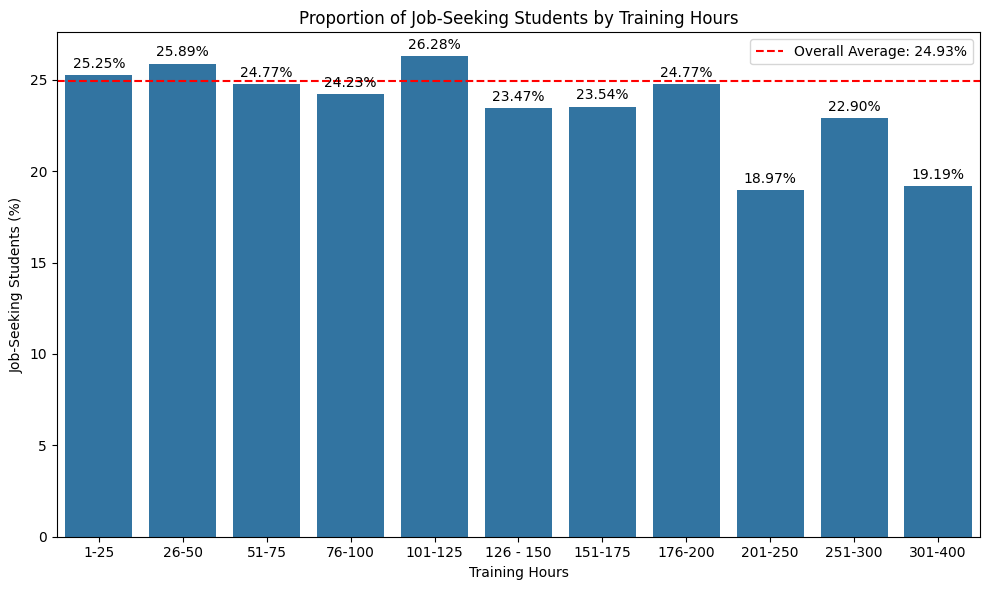

In [42]:
hours_plot = hours_analysis.reset_index()

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=hours_plot,
    x="hours_group",
    y="percentage",
    order=labels
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.axhline(
    y=average_percentage,
    color="red",
    linestyle="--",
    label=f"Overall Average: {average_percentage:.2f}%"
)

plt.xlabel("Training Hours")
plt.ylabel("Job-Seeking Students (%)")
plt.title("Proportion of Job-Seeking Students by Training Hours")
plt.legend()
plt.tight_layout()
plt.show()